# 12 · A directional upscaler: along the edge, never across it

Every model so far either computes a correction from a neighbourhood (notebooks 2 to 9) or
looks one up (notebooks 10 and 11). This one **chooses an interpolator**. Every output pixel
gets a few one-dimensional guesses - along its row, down its column, along a diagonal - and a
small network decides, per pixel, which of them to trust. Interpolating along an edge keeps it
sharp and interpolating across it is what blurs it, and on a screen most edges - text, rules,
window borders - run across or down. The design is the page "Directional 1D Upscaler"
(DirNet), on this project's data and in this project's frame:

    LR luma ──► candidate bank: one 5x5 convolution, 4 directions x 4 sub-pixels ──► PixelShuffle ──► 4 guesses per HR pixel ─────────┐
            └─► predictor: three 3x3 convolutions of 12 ──► two 1x1s: per sub-pixel 4 logits and a gate ──► PixelShuffle ──► softmax ──┴─► bicubic + gate x (blend - bicubic)
    colour: bicubic, as in notebook 7

- **The guesses are 1D kernels, learned.** Every sub-pixel gets four candidates. Each starts as
  the cubic interpolator along one line of LR pixels, and its taps learn - only on that line.
  All sixteen are one 5x5 convolution with sixteen outputs.
- **The choice is per pixel.** The predictor reads 7x7 LR pixels of luma and answers, for every
  sub-pixel, a softmax over its four candidates and a gate: how far to move from bicubic toward
  the blend. The gate is not squashed - above 1 it goes past the blend, which sharpens along the
  chosen direction.
- **It starts as bicubic**, like every model here: the gate's 1x1 starts at zero.
- **It corrects luma only**, as in notebook 7: the correction is added to R, G and B alike.

The page's ablation is this notebook's ladder, bicubic being its A:

| | variant | what it adds |
|---|---|---|
| B | `fixed` | the candidates, blended the same way everywhere: learned, linear, so one 5x5 filter |
| C | `adaptive` | the predictor: a blend chosen per pixel |
| D | `full` | C plus a learned correction from the predictor's features |

The page's question is whether C gets close to D for much less.

**Where this departs from the page, and why:**

- **No output pixel sits on an LR pixel.** The page draws a zero-inserted grid, where one pixel
  of every 2x2 block is a real one (R) and the other three sit between reals in a row (H), a
  column (V) or neither (D). The stream's downscale is centred - ffmpeg's, and the bicubic every
  notebook is scored against - so every HR pixel sits a quarter of an LR pixel from an LR
  pixel's centre along both axes (checked below: torch's bicubic weights are exactly the cubic
  kernel at ±1/4). The four sub-pixels are then one problem turned four ways. Each has its own
  row, its own column and the diagonal through it, all with LR pixels on the line: the page's 1D
  kernels. The fourth direction, the other diagonal, is the page's D gap - the sub-pixel sits
  halfway between two of its lines - and it gets the page's fix: interpolate across the lines,
  at the midpoint. Four candidates per sub-pixel, sixteen in all, where the page has twelve.
- **Bicubic is the base, not a candidate**, so that untrained the model is bicubic exactly; a
  softmax never puts all of its weight on one candidate.
- **Plain convolutions in the predictor.** The page trains them reparameterized; notebook 4
  measured reparameterization at nothing, three times over, and at 1e-3 it switched off 14 of
  the 16 channels of a narrow layer.
- **No temperature.** The 1x1 that makes the logits scales them itself, so a temperature is a
  parameter the model already has - and annealing one is a schedule the shared training loop
  does not run.
- **D's correction ends in a 1x1.** As drawn, two 3x3s after the predictor, it reaches 5 LR
  pixels: past the patches' halo of 4 and the client's, so trained it would learn from zero
  padding and tiled it would seam (notebook 4 caught two strategies doing that).
- **The blend runs after the PixelShuffle**, one HR channel per candidate, so its softmax is
  over the channels of an ordinary picture. There is no reshape to bake the tile's size into the
  graph, and the whole-frame graph is the tile's, reshaped.
- **This project's recipe.** `metrics.ssim_l1_loss` and the best epoch by luma SSIM, as notebooks
  2 to 11 train, rather than the page's L1 and then a JND loss, which this project does not have;
  colour bicubic rather than bilinear, since the skip makes it anyway.

Steps:

1. **Data** - the patch set, and what each validation patch shows.
2. **Model** - the candidates, the three variants, and the checks that they start where they
   should.
3. **Speed** - counted from the exported graphs, against notebook 7's model.
4. **Train** - each variant once; results overall, by content, which direction it picks, and
   pictures.
5. **Save** - the best, and check it loads back the same.
6. **Export** - every variant at the client's tile: float32, float16, and float16 as a whole
   1080p frame.

Needs: `00_data_preprocess.ipynb`. Writes `checkpoints/upscale_dirnet.pt` (the best) and each
run's training to `checkpoints/dirnet_runs/`.

In [2]:
"""Settings."""

import copy

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from torch.utils.data import DataLoader, Subset

from helpers import metrics, models, speed, tiles, training, webexport
from helpers.training import DATA_DIR, DEVICE

CHECKPOINT = training.CHECKPOINT_DIR / "upscale_dirnet.pt"   # the best variant
RUN_DIR = training.CHECKPOINT_DIR / "dirnet_runs"            # each run's training, saved every epoch
SPEED_DIR = training.CHECKPOINT_DIR / "speed"                # graphs exported only to be counted
BEFORE = training.CHECKPOINT_DIR / "upscale_strategies.pt"   # notebook 4's luma model: the one to beat

WIDTH = 12           # the predictor's channels (the page's)
MAX_EPOCHS = 500     # a safety limit; each training stops once it has converged
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
SEED = 0
SPREAD = 0.0003      # ssim-y: notebook 10's S network at three seeds on this patch set - what luck alone moves a score

STEP_WIDTH, STEP_HEIGHT = 320, 180       # LR pixels one client tile adds to the picture (notebook 5)
FRAME_WIDTH, FRAME_HEIGHT = 1920, 1080   # the whole-frame graph
ESTIMATE_ON = {"Iris Xe": "Intel Iris Xe, 96 EU (laptop iGPU)", "GTX 1650": "NVIDIA GTX 1650",
               "RTX 3060": "NVIDIA RTX 3060"}

training.seed_everything(SEED)

## 1. Data

The patch set of `00_data_preprocess.ipynb` - photos, videos and drawn desktop screens through
the stream's degradation - as notebooks 8 to 11 see it, with results split by what a patch
shows: the idea is for screens.

In [3]:
manifest = training.load_manifest()
training.describe(manifest)
SCALE = manifest["scale"]
train_loader, val_loader = training.loaders(DATA_DIR, manifest, BATCH_SIZE, val_batch_size=128)
trim = training.trimmer(manifest)


def content(source):
    """What a source shows: a drawn desktop screen, a photo (as a moving clip) or a video."""
    if source["dataset"] == "screens":
        return "screen"
    return "photo" if "motion" in source else "video"


by_content = {}   # what a patch shows -> the indices of its validation patches
for source in manifest["splits"]["val"]["sources"]:
    first, end = source["patches"]
    by_content.setdefault(content(source), []).extend(range(first, end))
print("val by content: " + ", ".join(f"{name} {len(indices):,}" for name, indices in by_content.items()))

device  cuda NVIDIA GeForce RTX 3090
scale   2
patch   72 px LR in (64 px + a halo of 4) -> 128 px HR out, 8 frames each
train  17140 patches from 1089 sources
val     3523 patches from 225 sources
val by content: photo 784, video 1,585, screen 1,154


## 2. Model

**Where the sub-pixels are.** At x2, LR pixel (i, j) answers for four HR pixels, its
sub-pixels, in `PixelShuffle`'s order: top left, top right, bottom left, bottom right. Each sits
a quarter of an LR pixel up or down, and left or right, of the pixel's centre.

**The candidates**, for the bottom-right sub-pixel - the other three are it mirrored - as taps
in the 5x5 LR window around the pixel, weighted to start with by the cubic kernel torch's bicubic
uses (a = -0.75) at each tap's distance along its line:

- **row** - the pixel's own row, at -1, 0, +1 and +2 columns; the sub-pixel is 1/4 of the way to
  the next column. Beside an edge that runs along the row, it never mixes in the row beyond it.
- **column** - the same, down the pixel's own column.
- **diagonal** - the diagonal through the pixel and the sub-pixel, which is 1/4 of the way to
  the diagonal neighbour.
- **other diagonal** - the sub-pixel sits halfway between two of its lines: the one through the
  pixel and the next one out. So the value on each of four lines (one pixel, or the mean of the
  two nearest the sub-pixel) is interpolated across the lines, at the midpoint. Six taps.

Each candidate's taps learn freely, but only those taps: a fixed mask. Every candidate starts
adding up to 1, so it keeps brightness.

**The variants:**

- `FixedDirections` (B): per sub-pixel, a softmax over its four candidates and a gate, learned
  but the same for every pixel. That is linear in the pixels, so it adds up to one 5x5 filter
  per sub-pixel, and it ships as that, folded into the bicubic skip: a single convolution, which
  costs exactly what bicubic as a convolution costs.
- `DirNet` (C): three 3x3 convolutions of 12 channels on the LR luma, then two 1x1s: 16 logits,
  a softmax over each sub-pixel's four candidates, and 4 gates. Both 1x1s start at zero, so
  untrained the weights are even and the gate is shut: bicubic.
- `DirNet(refine=True)` (D): C plus a 3x3 and a 1x1 on the predictor's features, the 1x1
  starting at zero, added to the luma correction - inside the halo of 4.

In [4]:
LUMA = torch.tensor(models.LUMA_709)
PHASES = 4                                                     # x2: the sub-pixels of an LR pixel
DIRECTIONS = ("row", "column", "diagonal", "other diagonal")   # every sub-pixel's candidates
K = len(DIRECTIONS)


def cubic(t, a=-0.75):
    """The cubic convolution kernel at distance `t`: Keys's, with torch's a = -0.75."""
    t = abs(t)
    if t <= 1:
        return (a + 2) * t ** 3 - (a + 3) * t ** 2 + 1
    if t < 2:
        return a * (t ** 3 - 5 * t ** 2 + 8 * t - 4)
    return 0.0


def side(phase, scale=2):
    """Which way a sub-pixel sits from its LR pixel's centre: (down, across), each -1 or 1."""
    return (1 if phase // scale else -1), (1 if phase % scale else -1)


def starting_taps(scale=2):
    """Every candidate's taps to start with, in the 5x5 LR window around a pixel: (K, PHASES, 5, 5)."""
    taps = torch.zeros(K, PHASES, 5, 5)
    along = [cubic(k - 0.25) for k in (-1, 0, 1, 2)]           # pixels -1..+2 on a line, the sub-pixel at +1/4
    across = [cubic(1.5), cubic(0.5), cubic(0.5), cubic(1.5)]  # lines -1..+2, the sub-pixel halfway from 0 to 1
    for p in range(PHASES):
        sy, sx = side(p, scale)
        for k, weight in zip((-1, 0, 1, 2), along):
            taps[0, p, 2, 2 + k * sx] = weight             # row
            taps[1, p, 2 + k * sy, 2] = weight             # column
            taps[2, p, 2 + k * sy, 2 + k * sx] = weight    # diagonal, through the sub-pixel
        # other diagonal: its lines are sy * down + sx * across = -1, 0, 1 and 2, and the sub-pixel is at 1/2
        taps[3, p, 2 - sy, 2] = taps[3, p, 2, 2 - sx] = across[0] / 2   # line -1: the two nearest pixels
        taps[3, p, 2, 2] = across[1]                                    # line 0: the pixel
        taps[3, p, 2 + sy, 2] = taps[3, p, 2, 2 + sx] = across[2] / 2   # line 1: the two nearest pixels
        taps[3, p, 2 + sy, 2 + sx] = across[3]                          # line 2: the diagonal neighbour
    return taps


def frozen(conv, weight, bias=None):
    """`conv` with these weights (and bias), never trained."""
    with torch.no_grad():
        conv.weight.copy_(weight.reshape(conv.weight.shape))
        if bias is not None:
            conv.bias.copy_(bias)
    for parameter in conv.parameters():
        parameter.requires_grad_(False)
    return conv


class CandidateBank(nn.Module):
    """Every candidate as one 5x5 convolution of the LR luma, no bias, and bicubic's sub-pixels
    as another, each PixelShuffled: a candidate is one channel at HR. A candidate learns only
    inside its taps; bicubic never changes."""

    def __init__(self, scale=2):
        super().__init__()
        start = starting_taps(scale).view(K * PHASES, 5, 5)   # channel k * PHASES + p: candidate k of sub-pixel p
        self.weight = nn.Parameter(start.clone())
        self.register_buffer("mask", (start != 0).float())
        self.register_buffer("bicubic", models.bicubic_kernel(scale, 5))
        self.shuffle = nn.PixelShuffle(scale)

    def kernels(self):
        return self.weight * self.mask

    def forward(self, luma):
        """(N, 1, h, w) LR luma -> the candidates (N, K, H, W) and bicubic (N, 1, H, W), at HR."""
        candidates = F.conv2d(luma, self.kernels()[:, None], padding=2)
        bicubic = F.conv2d(luma, self.bicubic[:, None], padding=2)
        return self.shuffle(candidates), self.shuffle(bicubic)


class FixedDirections(models.Upscaler):
    """Variant B: per sub-pixel, one softmax over its candidates and one gate, learned and the
    same for every pixel. Linear in the pixels, so it adds up to one 5x5 filter per sub-pixel."""

    def __init__(self, scale=2):
        super().__init__(scale, skip=5)
        self.to_luma = frozen(nn.Conv2d(3, 1, 1, bias=False), LUMA)
        self.bank = CandidateBank(scale)
        self.logits = nn.Parameter(torch.zeros(K, PHASES))   # even weights to start
        self.gate = nn.Parameter(torch.zeros(PHASES))        # shut to start: bicubic
        self.halo = self.skip_size // 2                      # 5x5 filters reach 2

    def kernel(self):
        """The filter of the luma correction, per sub-pixel: (PHASES, 5, 5)."""
        candidates = self.bank.kernels().view(K, PHASES, 5, 5)
        blend = (self.logits.softmax(dim=0)[..., None, None] * candidates).sum(dim=0)
        return self.gate[:, None, None] * (blend - self.bank.bicubic)

    def residual(self, x):
        correction = F.conv2d(self.to_luma(x), self.kernel()[:, None], padding=2)
        return torch.cat([correction, correction, correction], dim=1)   # on every colour: Y moves

    @torch.no_grad()
    def folded(self):
        """The same model as it ships: one convolution."""
        return OneFilter(self)


class OneFilter(nn.Module):
    """B folded: bicubic and its luma correction in one 5x5 convolution, then the PixelShuffle."""

    def __init__(self, model):
        super().__init__()
        self.scale, self.halo = model.scale, model.halo
        self.conv = copy.deepcopy(model.skip.conv)
        with torch.no_grad():
            kernel = model.kernel()
            luma = LUMA.to(kernel.device)[:, None, None]
            for colour in range(3):
                for p in range(PHASES):
                    self.conv.weight[colour * PHASES + p] += luma * kernel[p]   # the input's Y, filtered, on this colour
        self.shuffle = nn.PixelShuffle(model.scale)

    def forward(self, x):
        return self.shuffle(self.conv(x))


class DirNet(models.Upscaler):
    """Variants C and D: the blend chosen per pixel by a small network on the LR luma.

    Per HR pixel: luma = bicubic + gate x (sum over k of weight_k x candidate_k - bicubic), the
    weights a softmax over the K candidates. The blend runs after the PixelShuffle, where a
    candidate is one channel, so the softmax is over a picture's channels and the graph needs no
    reshape. With `refine`, a learned correction from the predictor's features is added too.
    """

    def __init__(self, width=WIDTH, refine=False, scale=2):
        super().__init__(scale, skip=5)
        self.width, self.refine = width, refine
        self.to_luma = frozen(nn.Conv2d(3, 1, 1, bias=False), LUMA)
        self.bank = CandidateBank(scale)
        layers, channels = [], 1
        for _ in range(3):
            layers += [nn.Conv2d(channels, width, 3, padding=1), nn.ReLU(inplace=True)]
            channels = width
        self.body = nn.Sequential(*layers)
        self.direction = models.zero_start(nn.Conv2d(width, K * PHASES, 1))   # the logits: even weights to start
        self.strength = models.zero_start(nn.Conv2d(width, PHASES, 1))        # the gate: shut to start
        if refine:
            self.polish = nn.Sequential(nn.Conv2d(width, width, 3, padding=1), nn.ReLU(inplace=True),
                                        models.zero_start(nn.Conv2d(width, PHASES, 1)))
        # the predictor's three 3x3s reach 3 LR pixels and the refine head's 3x3 one more; the candidates 2
        self.halo = 3 + int(refine)

    def choose(self, luma):
        """Per HR pixel: the K candidates' weights (N, K, H, W), adding up to 1, and the gate
        (N, 1, H, W); and the predictor's LR features."""
        features = self.body(luma)
        weights = self.shuffle(self.direction(features)).softmax(dim=1)
        return weights, self.shuffle(self.strength(features)), features

    def forward(self, x):
        luma = self.to_luma(x)
        candidates, bicubic = self.bank(luma)
        weights, gate, features = self.choose(luma)
        correction = gate * ((weights * candidates).sum(dim=1, keepdim=True) - bicubic)
        if self.refine:
            correction = correction + self.shuffle(self.polish(features))
        return self.shuffle(self.skip(x)) + correction   # the same on every colour: Y moves


VARIANTS = {   # name -> (class, arguments): the page's B, C and D
    "fixed": (FixedDirections, {}),
    "adaptive": (DirNet, {"refine": False}),
    "full": (DirNet, {"refine": True}),
}


def build(name):
    """A fresh, untrained variant."""
    model_class, arguments = VARIANTS[name]
    return model_class(scale=SCALE, **arguments).to(DEVICE)


def shipped(model):
    """What a variant runs as: B folded into one convolution, C and D as they are."""
    return model.folded() if isinstance(model, FixedDirections) else model


def learned(model):
    """How many numbers a variant learns: a candidate's taps count only inside its mask."""
    return models.count_parameters(model, True) - model.bank.weight.numel() + int(model.bank.mask.sum())

In [5]:
"""Checks: torch's bicubic is the cubic kernel a quarter pixel either side of the centre; every
candidate starts adding up to 1, the row and column ones are bicubic on a picture that varies one
way only, and the diagonal ones are exact where they should be; untrained, every variant is
bicubic; with random weights a flat grey stays flat; B as one convolution is B."""

models.check_skip_is_bicubic(SCALE)
gaps = {}

# bicubic's sub-pixels, read back from F.interpolate, against the cubic kernel at +-1/4
phases = models.bicubic_kernel(SCALE, 5)
for p in range(PHASES):
    sy, sx = side(p, SCALE)
    down = torch.tensor([cubic(i - sy / 4) for i in range(-2, 3)])
    across = torch.tensor([cubic(i - sx / 4) for i in range(-2, 3)])
    gaps[f"bicubic, sub-pixel {p}: the cubic kernel at {sy / 4:+.2f}, {sx / 4:+.2f}"] = (
        (phases[p] - torch.outer(down, across)).abs().max().item())
gaps["every candidate's taps add up to 1"] = (starting_taps(SCALE).sum(dim=(2, 3)) - 1).abs().max().item()

with torch.no_grad(), training.full_precision():
    bank = CandidateBank(SCALE).to(DEVICE)
    across_only = torch.rand(2, 1, 1, 40, device=DEVICE).expand(-1, -1, 40, -1)   # every row the same
    for k, picture, way in ((0, across_only, "across"), (1, across_only.transpose(2, 3), "down")):
        candidates, bicubic = bank(picture)
        gaps[f"{DIRECTIONS[k]} candidate against bicubic, on a picture that varies {way} only"] = (
            (candidates[:, k:k + 1] - bicubic)[..., 4:-4, 4:-4].abs().max().item())

    # pixels alike along every down-right diagonal: there the diagonal candidate of the top-left and
    # bottom-right sub-pixels, whose diagonal that is, gives back the pixel's own value; and on a
    # ramp across those diagonals, the other diagonal candidate of the top-right and bottom-left
    # sub-pixels, which sit halfway between two of them, gives the ramp where they sit
    y, x = torch.meshgrid(torch.arange(40.0, device=DEVICE), torch.arange(40.0, device=DEVICE), indexing="ij")
    alike = torch.rand(2, 79, device=DEVICE)[:, (x - y + 39).long()][:, None]
    ramp = ((x - y) / 80 + 0.5)[None, None]
    on_alike, on_ramp = bank(alike)[0], bank(ramp)[0]
    for p in range(PHASES):
        sy, sx = side(p, SCALE)
        dy, dx = p // SCALE, p % SCALE
        if sy == sx:
            gaps[f"diagonal candidate, sub-pixel {p}, on a picture alike along its diagonal"] = (
                (on_alike[:, 2:3, dy::2, dx::2] - alike)[..., 2:-2, 2:-2].abs().max().item())
        else:
            gaps[f"other diagonal candidate, sub-pixel {p}, on a ramp across its lines"] = (
                (on_ramp[:, 3:4, dy::2, dx::2] - (ramp + (sx - sy) / 4 / 80))[..., 2:-2, 2:-2].abs().max().item())

    probe_lr = next(iter(val_loader))[0][:8].to(DEVICE)
    bicubic = trim(models.bicubic(probe_lr, SCALE))
    grey = torch.full((2, 3, 40, 40), 0.4, device=DEVICE)
    for name in VARIANTS:
        model = build(name)
        assert model.halo <= manifest["halo"], f"{name} reaches further than the patches' halo"
        gaps[f"{name}: untrained, against bicubic"] = (trim(model(probe_lr)) - bicubic).abs().max().item()
        # random weights everywhere but in the candidates (which would stop adding up to 1) and in
        # D's correction (which may add what it likes): what is left is the blend, whose weights
        # must add up to 1 at every pixel
        torch.manual_seed(1)
        for parameter_name, parameter in model.named_parameters():
            if parameter.requires_grad and not parameter_name.startswith(("bank.", "polish.")):
                parameter.normal_(0, 0.3)
        edge = SCALE * (model.halo + 1)   # zero padding reaches no further in
        gaps[f"{name}: random weights, a flat grey"] = (model(grey) - 0.4)[..., edge:-edge, edge:-edge].abs().max().item()
        if name == "fixed":
            gaps["fixed: as one convolution, against itself"] = training.assert_same_model(model, model.folded())

for name, gap in gaps.items():
    assert gap < 1e-5, f"{name}: {gap:.1e}"
print("exact, to float32 rounding:")
for name, gap in gaps.items():
    print(f"  {name:<72}{gap:.0e}")
print()
for name in VARIANTS:
    model = build(name)
    print(f"{name:<9} halo {model.halo}   {learned(model):5,} learned parameters")

exact, to float32 rounding:
  bicubic, sub-pixel 0: the cubic kernel at -0.25, -0.25                  0e+00
  bicubic, sub-pixel 1: the cubic kernel at -0.25, +0.25                  0e+00
  bicubic, sub-pixel 2: the cubic kernel at +0.25, -0.25                  0e+00
  bicubic, sub-pixel 3: the cubic kernel at +0.25, +0.25                  0e+00
  every candidate's taps add up to 1                                      0e+00
  row candidate against bicubic, on a picture that varies across only     1e-07
  column candidate against bicubic, on a picture that varies down only    2e-07
  diagonal candidate, sub-pixel 0, on a picture alike along its diagonal  6e-08
  other diagonal candidate, sub-pixel 1, on a ramp across its lines       6e-08
  other diagonal candidate, sub-pixel 2, on a ramp across its lines       6e-08
  diagonal candidate, sub-pixel 3, on a picture alike along its diagonal  6e-08
  fixed: untrained, against bicubic                                       4e-07
  fixed: ran

## 3. Speed

Counted the way notebooks 3, 4 and 8 to 11 count: operations and memory traffic in the exported
ONNX graph at the client's tile, per LR pixel, and the roofline estimate for a 1080p frame at the
share of its peak this computer's GPU reaches on notebook 7's model in torch. The graphs are
untrained: the work does not depend on the weights. B is counted as it ships, one convolution.

Besides `Conv`, `Relu`, `Add` and `DepthToSpace`, C and D need `Softmax` to weigh the candidates,
`Mul` and `ReduceSum` to blend them, and `Sub` and `Mul` for the gate: a choice per pixel is a
product of two pictures, which no convolution makes. All four are outside the budget the browser
has been measured on; B needs none of them. Blending after the PixelShuffle costs four more
`DepthToSpace`s - the candidates, bicubic, the logits and the gate, 40 float32 values read and
written per LR pixel, about a sixth of C's memory traffic - for a graph with no reshape.

In [6]:
plan = tiles.plan_tiling((FRAME_WIDTH, FRAME_HEIGHT), scale=SCALE, halo=manifest["halo"])
tile_shape = plan["input"][2:]   # (height, width) of one tile, halo included
frame_lr = torch.rand(1, 3, FRAME_HEIGHT // SCALE, FRAME_WIDTH // SCALE, device=DEVICE)


def frame_work(cost, pixels, runs):
    """Operations and bytes for `pixels` LR pixels, computed in `runs` runs of the graph."""
    return {"operations": pixels * cost["ops"], "bytes": pixels * cost["bytes"] + runs * cost["weight_bytes"]}


def cost(model, name):
    """Operations and bytes per LR pixel of a model's graph at the client's tile, and the
    milliseconds of a 1080p frame through it in torch on this computer."""
    model = model.to(DEVICE).eval()
    graph = webexport.export(model, f"speed_check_{name}.onnx", tile_shape, halo=model.halo, models_dir=SPEED_DIR)
    work = webexport.count_work(graph["path"])
    with torch.no_grad():
        measured_ms = speed.time_ms(lambda: model(frame_lr), seconds=1.0)
    return {"ops": work["operations"] / work["input_pixels"], "bytes": work["activation_bytes"] / work["input_pixels"],
            "weight_bytes": work["weight_bytes"], "measured_ms": measured_ms, "graph": graph}


costs = {"notebook 7": cost(models.LumaUpscaler((24,), 2, 3, scale=SCALE), "luma_24x2")}
for name in VARIANTS:
    costs[name] = cost(shipped(build(name)), f"dirnet_{name}")

# calibrate on notebook 7's model, run as one whole frame
reference = costs["notebook 7"]
whole_frame = frame_work(reference, frame_lr.shape[2] * frame_lr.shape[3], runs=1)
efficiency = (speed.roofline_ms(whole_frame, *speed.HARDWARE[speed.THIS_GPU])[0] / reference["measured_ms"]
              if DEVICE.type == "cuda" else 1.0)
print(f"estimates at {efficiency:.0%} of each device's peak (notebook 7's model here)\n")
print(f"{'':<14}{'ops / LR px':>12}{'bytes / LR px':>15}{'weights, KB':>13}{'here, ms':>10}"
      + "".join(f"{short + ', ms':>14}" for short in ESTIMATE_ON))
tiled_pixels = plan["runs"] * tile_shape[0] * tile_shape[1]
for name, c in costs.items():
    estimates = [speed.roofline_ms(frame_work(c, tiled_pixels, plan["runs"]), *speed.HARDWARE[device])
                 for device in ESTIMATE_ON.values()]
    print(f"{name:<14}{c['ops']:12,.0f}{c['bytes']:15,.0f}{c['weight_bytes'] / 1e3:13.1f}{c['measured_ms']:10.2f}"
          + "".join(f"{ms / efficiency:7.1f} ({limit[0]})".rjust(14) for ms, limit in estimates))
print("\n(c) compute-bound, (m) memory-bound")
for c in costs.values():
    print(webexport.summary_line(c["graph"]))

estimates at 41% of each device's peak (notebook 7's model here)

               ops / LR px  bytes / LR px  weights, KB  here, ms   Iris Xe, ms  GTX 1650, ms  RTX 3060, ms
notebook 7          28,120          2,536         56.2      3.43      50.6 (m)      26.9 (m)       9.6 (m)
fixed                1,800            156          3.6      0.24       3.1 (m)       1.7 (m)       0.6 (m)
adaptive             8,878          1,896         17.6      2.27      37.8 (m)      20.1 (m)       7.1 (m)
full                11,598          2,232         22.8      2.79      44.5 (m)      23.7 (m)       8.4 (m)

(c) compute-bound, (m) memory-bound
speed_check_luma_24x2.onnx                             57.6 KB   Addx3, Concatx1, Convx7, DepthToSpacex1, Relux3
speed_check_dirnet_fixed.onnx                           4.0 KB   Convx1, DepthToSpacex1
speed_check_dirnet_adaptive.onnx                       20.9 KB   Addx1, Constantx1, Convx9, DepthToSpacex5, Mulx2, ReduceSumx1, Relux3, Softmaxx1, Subx1   OUTSID

## 4. Train

The recipe of notebooks 2 to 11: Adam from 1e-3, batch 32, `metrics.ssim_l1_loss`, the epoch
with the best luma SSIM kept, each run trained until it has converged. Each variant trains once.
The ruler is notebook 10's - its smallest network at three seeds landed 0.0003 SSIM-Y apart on
this patch set - so a gap narrower than that is luck. If C and D land within it of each other, a
second seed of each is the run to add.

Each run saves its training to `checkpoints/dirnet_runs/` after every epoch: run the cell again
after an interruption and it carries on; finished runs just load.

In [7]:
def train(name):
    """Train a fresh variant, or load its saved training. Returns it at its best epoch, its
    history and its best epoch."""
    torch.manual_seed(SEED)
    model = build(name)
    torch.manual_seed(SEED)   # the same batches in the same order, whatever the model
    history, best = training.train(model, train_loader, val_loader, trim, MAX_EPOCHS, learning_rate=LEARNING_RATE,
                                   loss_fn=metrics.ssim_l1_loss, select="ssim", checkpoint=RUN_DIR / f"{name}.pt",
                                   verbose=0)
    print(f"{name:<10} best epoch {best['epoch']:3} of {len(history):3}, ssim-y {best['score']:.4f}")
    return model, history, best


trained, histories, bests = {}, {}, {}
for name in VARIANTS:
    trained[name], histories[name], bests[name] = train(name)

# notebook 4's winner, the same body as notebook 7's: the model to beat
before = training.load_checkpoint(BEFORE)
trained["notebook 4's model"] = getattr(models, before["architecture"])(scale=SCALE, **before["arguments"]).to(DEVICE)
trained["notebook 4's model"].load_state_dict(before["state_dict"])
print(f"notebook 4's model: its {before['strategy']}, loaded")

fixed      best epoch  53 of  71, ssim-y 0.9096
adaptive   best epoch 133 of 157, ssim-y 0.9277
full       best epoch 126 of 138, ssim-y 0.9303
notebook 4's model: its luma 24 + 2 blocks, loaded


### The result

Every model on the whole validation set - the 128 px cores, as every notebook scores - with the
operations its graph takes per LR pixel and its weights in float16. **better** / **worse** means
a gap wider than the ruler; **luck** means this set cannot tell the two apart. On the same set,
notebook 10's fine-tuned tables score 0.9251 (`S`) and 0.9343 (`SDY x2`) ssim-y, and notebook 4's
model 0.9292.

The questions, in order: what each variant gains over bicubic, what a choice per pixel buys over
one blend for all (C over B), what the learned correction adds (D over C), and how far notebook
4's model still is.

In [8]:
BASELINES = {"bicubic": models.Resize(SCALE), "nearest": models.Resize(SCALE, "nearest")}


def score(name, indices=None):
    """`metrics.report` of one model (or baseline) on the validation patches `indices` (None: all)."""
    dataset = val_loader.dataset if indices is None else Subset(val_loader.dataset, indices)
    model = BASELINES[name] if name in BASELINES else trained[name]
    return training.evaluate(model.to(DEVICE), DataLoader(dataset, batch_size=128), trim)


def cost_columns(name, scores):
    """The last columns: operations per LR pixel of the model's graph, and its KB in float16."""
    if name in BASELINES:
        return ""
    row = costs["notebook 7" if name == "notebook 4's model" else name]
    return f"{row['ops']:12,.0f}{row['weight_bytes'] / 2e3:9.1f}"


def compare(a, b, label):
    word = "luck" if abs(a - b) <= SPREAD else ("better" if a > b else "worse")
    print(f"{label:<44}{a - b:+.4f} ssim-y  {word}")


results = {name: score(name) for name in [*BASELINES, *trained]}
print(f"The ruler: {SPREAD:.4f} ssim-y. Last columns: operations per LR pixel, and KB in float16.")
metrics.print_table(results, extra=cost_columns)

best_name = max(VARIANTS, key=lambda name: results[name]["ssim"])
print()
for name in VARIANTS:
    compare(results[name]["ssim"], results["bicubic"]["ssim"], f"{name} over bicubic")
compare(results["adaptive"]["ssim"], results["fixed"]["ssim"], "adaptive over fixed: a choice per pixel")
compare(results["full"]["ssim"], results["adaptive"]["ssim"], "full over adaptive: the learned correction")
compare(results["notebook 4's model"]["ssim"], results[best_name]["ssim"], f"notebook 4's model over {best_name}")

The ruler: 0.0003 ssim-y. Last columns: operations per LR pixel, and KB in float16.
                        wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
bicubic                 34.14    33.18    50.67    51.46     32.02   0.9049
nearest                 32.39    31.36    50.33    51.12     30.52   0.8887
fixed                   34.32    33.35    50.66    51.45     32.17   0.9096       1,800      1.8
adaptive                34.74    33.80    50.69    51.47     32.49   0.9277       8,878      8.8
full                    35.12    34.22    50.70    51.48     32.81   0.9303      11,598     11.4
notebook 4's model      35.33    34.45    50.70    51.49     32.96   0.9292      28,120     28.1

fixed over bicubic                          +0.0046 ssim-y  better
adaptive over bicubic                       +0.0227 ssim-y  better
full over bicubic                           +0.0254 ssim-y  better
adaptive over fixed: a choice per pixel     +0.0181 ssim-y  better
full over adaptive: the learned

### By content

The gain over bicubic on screens, photos and video apart: luma SSIM, and luma PSNR in dB.

In [9]:
SHOW = [*VARIANTS, "notebook 4's model"]
print(f"{'':<8}{'patches':>8}{'bicubic ssim-y':>16}" + "".join(f"{name:>22}" for name in SHOW))
for value, indices in by_content.items():
    base = score("bicubic", indices)
    row = f"{value:<8}{len(indices):8,}{base['ssim']:16.4f}"
    for name in SHOW:
        scores = score(name, indices)
        row += f"{scores['ssim'] - base['ssim']:+.4f} / {scores['y'] - base['y']:+.2f}".rjust(22)
    print(row)

         patches  bicubic ssim-y                 fixed              adaptive                  full    notebook 4's model
photo        784          0.8359       +0.0071 / +0.14       +0.0150 / +0.21       +0.0162 / +0.29       +0.0217 / +0.74
video      1,585          0.9535       -0.0001 / +0.11       +0.0081 / +0.22       +0.0100 / +0.63       +0.0122 / +1.20
screen     1,154          0.8851       +0.0095 / +0.30       +0.0481 / +1.46       +0.0526 / +2.11       +0.0425 / +1.75


### Which direction it picks

For C and D, over the cores of the validation patches, at the HR pixels where the choice matters:
where the four cubic interpolators - the candidates as they start, so the same pixels for every
model - are more than 4 of 255 steps apart, which is an edge or a texture. On a flat area they
all say the same, and which one is heaviest means nothing. There: the share of pixels whose
heaviest candidate is each direction, and the mean gate - 0 is bicubic, 1 the blend, above 1
past it. If the idea holds, screens lean on rows and columns, and photos and video spread their
weight. Then, for four held-out screens, C's heaviest candidate and its gate where the choice
matters (grey elsewhere).

                    matters             row          column        diagonal  other diagonal  mean gate
adaptive  photo       36.1%           37.4%           17.7%           12.1%           32.9%       0.36
adaptive  video       16.7%           35.1%           19.5%           11.0%           34.4%       0.32
adaptive  screen      22.4%           31.1%           26.1%           12.6%           30.3%       0.45
full      photo       36.1%           38.9%           12.4%           25.1%           23.6%       0.39
full      video       16.7%           37.4%           14.2%           25.6%           22.9%       0.42
full      screen      22.4%           36.7%           21.1%           21.1%           21.2%       0.52


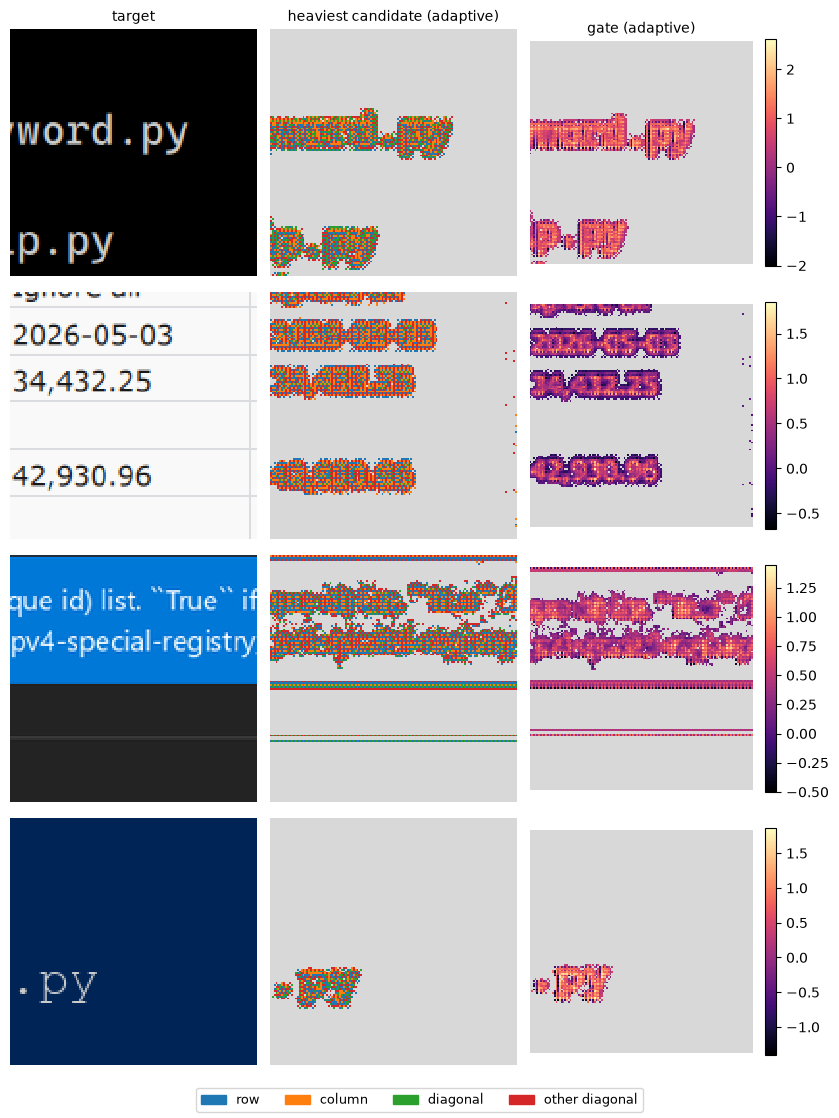

In [10]:
DISAGREE = 4 / 255                             # the cubic interpolators further apart than this: the choice matters
CUBIC = CandidateBank(SCALE).to(DEVICE).eval()   # the candidates as they start


@torch.no_grad()
def choice(model, lr):
    """Per HR pixel of the cores: the heaviest candidate (N, H, W), the gate (N, H, W), and
    whether the choice matters there (N, H, W)."""
    luma = model.to_luma(lr)
    candidates, _ = CUBIC(luma)
    weights, gate, _ = model.choose(luma)
    candidates, weights, gate = trim(candidates), trim(weights), trim(gate)[:, 0]
    return weights.argmax(dim=1), gate, candidates.amax(dim=1) - candidates.amin(dim=1) > DISAGREE


def picks(model, indices):
    """Over the cores of these validation patches: the share of HR pixels where the choice
    matters, and there, the share whose heaviest candidate is each direction and the mean gate."""
    model.eval()
    counts, gates, pixels = torch.zeros(K, device=DEVICE), 0.0, 0
    for lr, _ in DataLoader(Subset(val_loader.dataset, indices), batch_size=128):
        heaviest, gate, matters = choice(model, lr.to(DEVICE))
        counts += torch.bincount(heaviest[matters], minlength=K)
        gates += gate[matters].sum().item()
        pixels += matters.numel()
    chosen = counts.sum().item()
    return chosen / pixels, counts / chosen, gates / chosen


print(f"{'':<18}{'matters':>9}" + "".join(f"{direction:>16}" for direction in DIRECTIONS) + f"{'mean gate':>11}")
for name in ("adaptive", "full"):
    for value, indices in by_content.items():
        matters, shares, gate = picks(trained[name], indices)
        print(f"{name:<10}{value:<8}{matters:9.1%}" + "".join(f"{share:16.1%}" for share in shares.tolist())
              + f"{gate:11.2f}")

shown = by_content["screen"][::max(1, len(by_content["screen"]) // 4)][:4]
lr = torch.stack([val_loader.dataset[i][0] for i in shown]).to(DEVICE)
hr = torch.stack([val_loader.dataset[i][1] for i in shown])
heaviest, gate, matters = (part.cpu().numpy() for part in choice(trained["adaptive"].eval(), lr))

colours = ListedColormap(plt.cm.tab10.colors[:K]).with_extremes(bad="0.85")
fig, axes = plt.subplots(len(shown), 3, figsize=(8.4, 2.8 * len(shown)), squeeze=False)
for row in range(len(shown)):
    axes[row][0].imshow(hr[row].permute(1, 2, 0).numpy(), interpolation="nearest")
    axes[row][1].imshow(np.ma.masked_where(~matters[row], heaviest[row]), cmap=colours, vmin=-0.5, vmax=K - 0.5,
                        interpolation="nearest")
    fig.colorbar(axes[row][2].imshow(np.ma.masked_where(~matters[row], gate[row]),
                                     cmap=plt.get_cmap("magma").with_extremes(bad="0.85"), interpolation="nearest"),
                 ax=axes[row][2], fraction=0.046)
    for ax in axes[row]:
        ax.axis("off")
for ax, title in zip(axes[0], ("target", "heaviest candidate (adaptive)", "gate (adaptive)")):
    ax.set_title(title, fontsize=10)
fig.legend(handles=[Patch(color=colours(k), label=direction) for k, direction in enumerate(DIRECTIONS)],
           loc="lower center", ncol=K, fontsize=9)
fig.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

### What it looks like

The same four screens: bicubic, the three variants, notebook 4's model and the target. Look at
the strokes of the text - a sharp one running across or down is the case the idea is for.

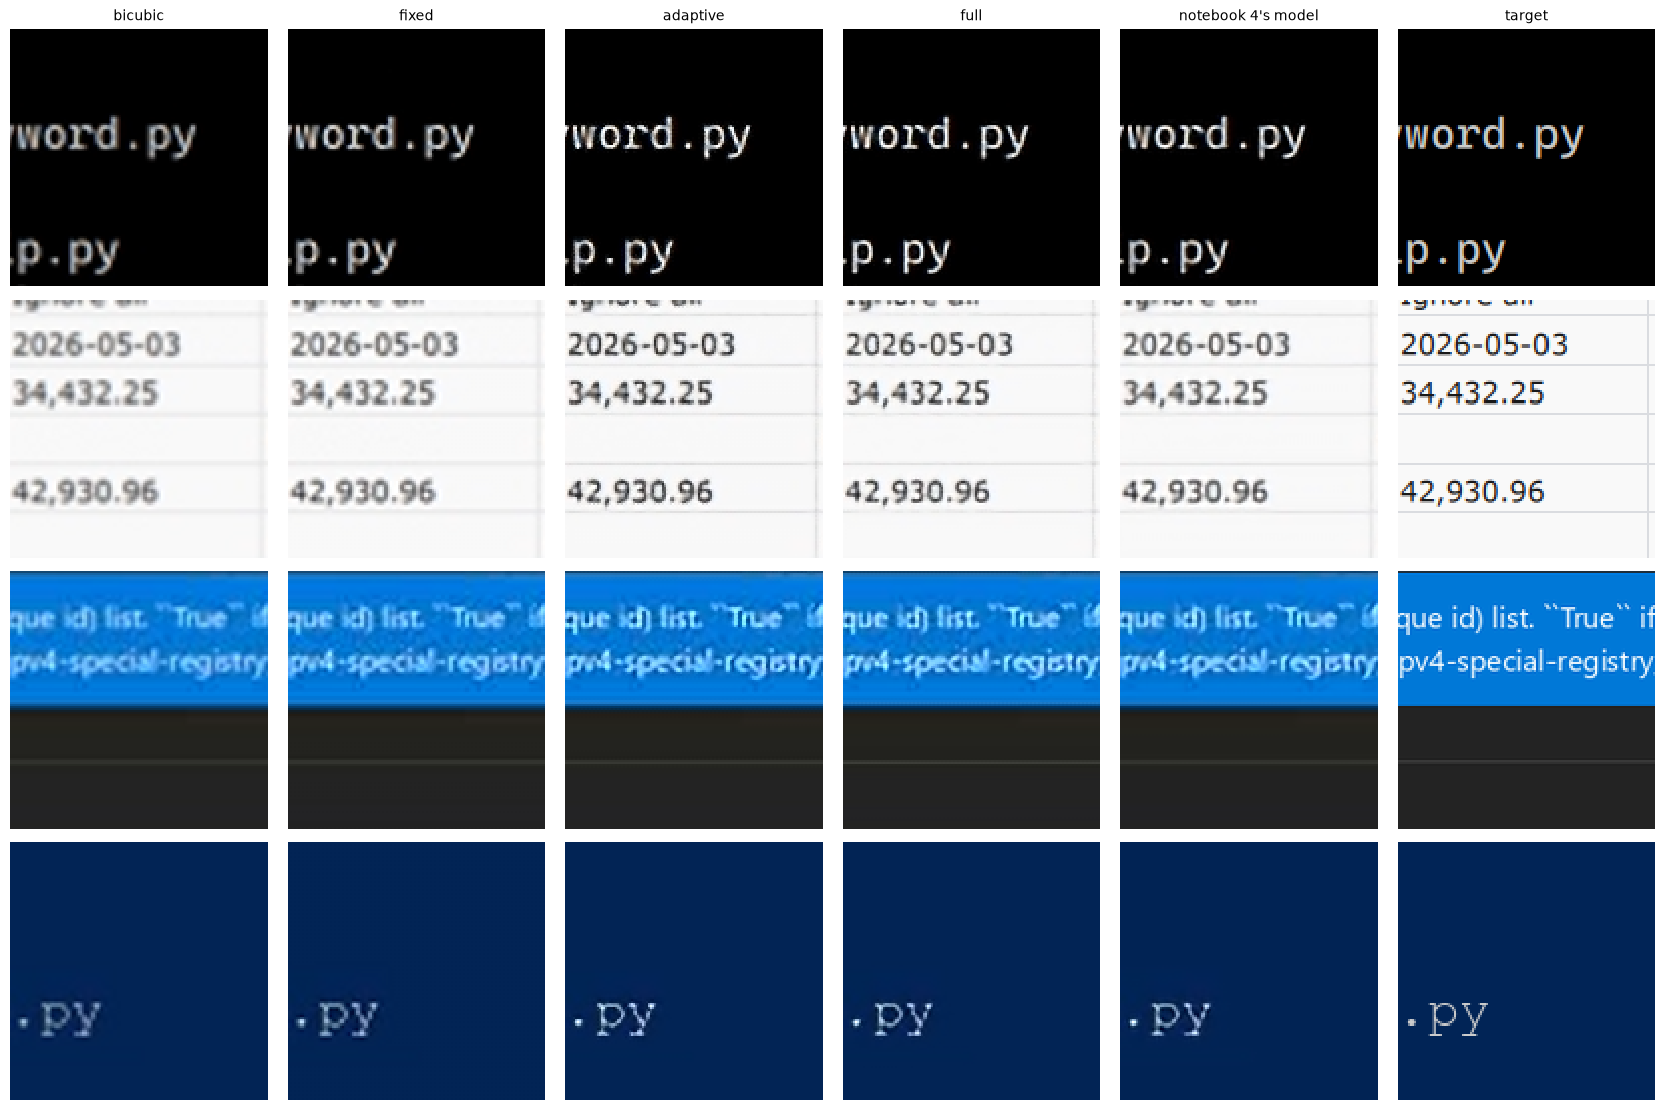

In [11]:
with torch.no_grad():
    training.show_patches({"bicubic": trim(models.bicubic(lr, SCALE)),
                           **{name: trim(trained[name].eval()(lr)) for name in VARIANTS},
                           "notebook 4's model": trim(trained["notebook 4's model"].eval()(lr)),
                           "target": hr})

## 5. Save and reload

The best variant by luma SSIM is saved with everything needed to rebuild it. We load it into a
fresh model and check it computes the same thing.

In [12]:
best = trained[best_name]
training.save_checkpoint(CHECKPOINT, best, architecture=type(best).__name__, arguments=VARIANTS[best_name][1],
                         scale=SCALE, halo=best.halo, loss="ssim_l1_loss", select="ssim",
                         epochs=len(histories[best_name]), best_epoch=bests[best_name]["epoch"],
                         val=results[best_name], val_bicubic=results["bicubic"], seed_spread=SPREAD,
                         degradation=manifest["degradation"])

# rebuild it from the file alone, the way a later notebook would
checkpoint = training.load_checkpoint(CHECKPOINT)
model_class = {"FixedDirections": FixedDirections, "DirNet": DirNet}[checkpoint["architecture"]]
loaded = model_class(scale=checkpoint["scale"], **checkpoint["arguments"]).to(DEVICE)
loaded.load_state_dict(checkpoint["state_dict"])
training.assert_same_model(best, loaded)
print("reloaded model is identical")

saved /home/henrik/desktop-streamer-ai/src/upscale/checkpoints/upscale_dirnet.pt (32 KB)
reloaded model is identical


## 6. Export for the browser

Every variant at the client's tile (a 320x180 step): float32, float16, and float16 as a whole
1080p frame. B goes as one convolution - the cheapest learned model there is - and C and D as
they are, since what a choice per pixel costs in a browser is the page's question. Every
operator reads its size from its input, so the whole-frame graph is the tile's, reshaped.

In [13]:
def input_shape(step_height, step_width, halo):
    """The model input for a step: the step plus the halo on every side, as (height, width)."""
    return (step_height + 2 * halo, step_width + 2 * halo)


def check_and_time(info, module, shape, dtype, tolerance):
    """Check a written graph against the torch module, time it on the CPU, print one line."""
    webexport.check_graph(info["path"], module, np.random.rand(1, 3, *shape).astype(np.float32), dtype, tolerance)
    ms = webexport.time_graph(info["path"], shape, dtype)
    webexport.annotate(info, cpu_ms=round(ms, 2))
    print(webexport.summary_line(info, ms))


tile_name = f"tile{STEP_WIDTH}x{STEP_HEIGHT}"
for name in VARIANTS:
    tag = f"dirnet_{name}"
    module = shipped(trained[name]).eval()
    tile_shape = input_shape(STEP_HEIGHT, STEP_WIDTH, module.halo)
    frame_shape = input_shape(FRAME_HEIGHT // SCALE, FRAME_WIDTH // SCALE, module.halo)

    fp32 = webexport.export(module, f"upscale_{tag}_{tile_name}.onnx", tile_shape, label=f"{tag} fp32", halo=module.halo)
    check_and_time(fp32, module, tile_shape, np.float32, tolerance=2e-3)

    fp16 = webexport.to_float16(fp32, f"upscale_{tag}_fp16_{tile_name}.onnx")
    webexport.write_metadata(fp16["path"], {"label": f"{tag} fp16"})
    check_and_time(fp16, module, tile_shape, np.float16, tolerance=4e-3)

    frame = webexport.to_frame(fp16, f"upscale_{tag}_fp16_{tile_name}_frame.onnx", FRAME_WIDTH, FRAME_HEIGHT)
    check_and_time(frame, module, frame_shape, np.float16, tolerance=4e-3)
print("compare in a browser: uv run src/upscale/benchmark/main.py")

upscale_dirnet_fixed_tile320x180.onnx                   4.0 KB    1.15 ms   Convx1, DepthToSpacex1
upscale_dirnet_fixed_fp16_tile320x180.onnx              2.3 KB    1.16 ms   Convx1, DepthToSpacex1
upscale_dirnet_fixed_fp16_tile320x180_frame.onnx        2.3 KB   12.26 ms   Convx1, DepthToSpacex1
upscale_dirnet_adaptive_tile320x180.onnx               20.9 KB   11.76 ms   Addx1, Constantx1, Convx9, DepthToSpacex5, Mulx2, ReduceSumx1, Relux3, Softmaxx1, Subx1   OUTSIDE BUDGET: Mul, ReduceSum, Softmax, Sub
upscale_dirnet_adaptive_fp16_tile320x180.onnx          13.5 KB    6.32 ms   Addx1, Constantx1, Convx9, DepthToSpacex5, Mulx2, ReduceSumx1, Relux3, Softmaxx1, Subx1   OUTSIDE BUDGET: Mul, ReduceSum, Softmax, Sub
upscale_dirnet_adaptive_fp16_tile320x180_frame.onnx    13.5 KB   78.71 ms   Addx1, Constantx1, Convx9, DepthToSpacex5, Mulx2, ReduceSumx1, Relux3, Softmaxx1, Subx1   OUTSIDE BUDGET: Mul, ReduceSum, Softmax, Sub
upscale_dirnet_full_tile320x180.onnx                   27.1 KB   14.19